# BERT on SST-5: fine-grained sentiment, step by step

**Goal:** understand what a classic encoder model (BERT) can and cannot do on a hard 5-class rating task, and see which fine-tuning techniques actually help.

**How to run (Google Colab):** `Runtime > Change runtime type > T4 GPU`, then `Runtime > Run all`.

| Section | What you do |
|---|---|
| 1 | Gather and describe SST-5 |
| 2 | Look at the data (examples, class balance, lengths, tokens, telltale words) |
| 3 | Run BERT: untrained, frozen features, naive fine-tuning |
| 4 | Try your own sentences and compare with your own ratings |
| 5 | Reflection and take-aways |

Every section ends with an **Interpretation** cell. The numbers quoted there are typical ranges, not guarantees: your results will differ a little by seed and library version.

In [ ]:
%pip install -q -U datasets transformers -q

In [ ]:
import gc, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import os
import logging
from torch.utils.data import DataLoader
from IPython.display import display
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


logging.getLogger("huggingface_hub.repocard").setLevel(logging.ERROR)
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
warnings.filterwarnings("ignore")

# ---------------- Global settings ----------------
SEED = 42
MODEL_NAME = "bert-base-uncased"
LARGE_MODEL = "bert-large-uncased"   # you can also try "roberta-large"
RUN_LARGE = True                     # False = skip the slowest experiment
RUN_SEED_CHECK = True                # False = skip the extra seeds (saves ~5 min)
MAX_LEN = 128
LABELS = ["very negative", "negative", "neutral", "positive", "very positive"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"      # mixed precision: faster on GPU

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("Device:", device, "|",
      torch.cuda.get_device_name(0) if USE_AMP else "No GPU found. Use Runtime > Change runtime type > T4 GPU")

Device: cuda | Tesla T4


## 1. SST-5: data gathering and description

**What it is.** The *Stanford Sentiment Treebank (SST)* contains 11,855 sentences taken from Rotten Tomatoes movie reviews. Human annotators rated the sentiment of each sentence (and of many sub-phrases) on a continuous slider; those scores were then cut into **five bins** i.e., SST-5:

`0 very negative` | `1 negative` | `2 neutral` | `3 positive` | `4 very positive`


We load the sentence-level version from the Hugging Face Hub (`SetFit/sst5`), which comes with the standard train / validation / test split. If that id ever fails to load, search "sst5" on the Hub and use the `namespace/name` shown there; it needs the columns `text` and `label`.

In [ ]:
raw = load_dataset("SetFit/sst5")
print(raw)

train_df = raw["train"].to_pandas()
val_df   = raw["validation"].to_pandas()
test_df  = raw["test"].to_pandas()
assert {"text", "label"} <= set(train_df.columns), "Unexpected columns, check the dataset id"


# sanity check: does our label order match the dataset's own label names?
if "label_text" in train_df.columns:
    print("\nLabel id -> dataset label name:")
    print(train_df.groupby("label")["label_text"].first().to_string())

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 8544
    })
    validation: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1101
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 2210
    })
})

Label id -> dataset label name:
label
0    very negative
1         negative
2          neutral
3         positive
4    very positive


In [ ]:
splits = {"train": train_df, "validation": val_df, "test": test_df}

summary = pd.DataFrame({
    "sentences": {s: len(d) for s, d in splits.items()},
    "avg words": {s: round(d.text.str.split().str.len().mean(), 1) for s, d in splits.items()},
    "max words": {s: int(d.text.str.split().str.len().max()) for s, d in splits.items()},
})
display(summary)

dist = pd.DataFrame({s: d.label.value_counts(normalize=True).sort_index() * 100 for s, d in splits.items()})
dist.index = LABELS
print("Class distribution (% of each split):")
display(dist.round(1))

majority = train_df.label.mode()[0]
print(f"Chance level (5 classes): 20.0%")
print(f"Majority-class baseline (always predict '{LABELS[majority]}'): "
      f"{(test_df.label == majority).mean():.1%} test accuracy")

,sentences,avg words,max words
train,8544,19.1,52
validation,1101,19.3,49
test,2210,19.2,56


Class distribution (% of each split):


,train,validation,test
very negative,12.8,12.6,12.6
negative,26.0,26.2,28.6
neutral,19.0,20.8,17.6
positive,27.2,25.3,23.1
very positive,15.1,15.0,18.1


Chance level (5 classes): 20.0%
Majority-class baseline (always predict 'positive'): 23.1% test accuracy


### Section 1

- The split is roughly **8.5k train / 1.1k validation / 2.2k test**: small by modern standards. Small data plus subtle labels is part of why SST-5 is hard.
- The classes are **not perfectly balanced**. "negative" and "positive" are the biggest; "very negative" is the smallest. So plain accuracy should always be compared to the **majority-class baseline** (about 28% on test), not only to 20% chance.
- Sentences are short (about 19 words on average), so a short `max_length` is fine and training is cheap.
- We will use **validation** to make every decision (which epoch, which technique) and look at **test** only to report results. Choosing things by test accuracy would quietly inflate the numbers.

## 2. SST-5: data demonstration

Before modelling, look at the data. We check (a) real examples per class, (b) class balance and length, (c) how BERT's tokenizer sees a sentence, (d) which words tell the classes apart.

In [ ]:
pd.set_option("display.max_colwidth", 200)
for k, name in enumerate(LABELS):
    print(f"\n=== {k}: {name} ===")
    for t in train_df[train_df.label == k].sample(3, random_state=1).text:
        print("  -", t)


=== 0: very negative ===
  - it 's a terrible movie in every regard , and utterly painful to watch .
  - the country bears wastes an exceptionally good idea .
  - there is no psychology here , and no real narrative logic -- just a series of carefully choreographed atrocities , which become strangely impersonal and abstract .

=== 1: negative ===
  - cherish is a dud -- a romantic comedy that 's not the least bit romantic and only mildly funny .
  - the story has little wit and no surprises .
  - the story is -- forgive me -- a little thin , and the filmmaking clumsy and rushed .

=== 2: neutral ===
  - too many improbabilities and rose-colored situations temper what could 've been an impacting film .
  - if the movie were all comedy , it might work better .
  - like a poor man 's you can count on me

=== 3: positive ===
  - it is as uncompromising as it is nonjudgmental , and makes clear that a prostitute can be as lonely and needy as any of the clients .
  - less the sensational true

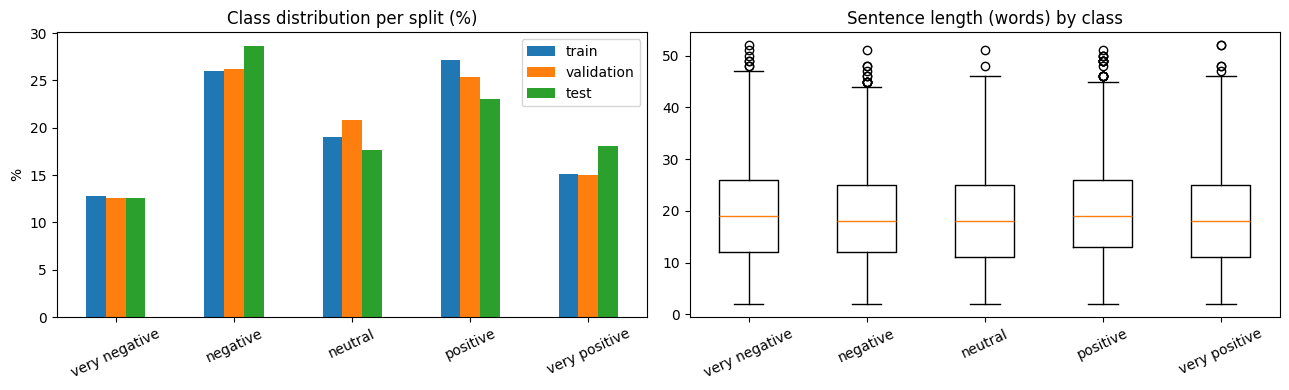

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

dist.plot(kind="bar", ax=ax[0], rot=25)
ax[0].set_title("Class distribution per split (%)"); ax[0].set_ylabel("%")

words = train_df.text.str.split().str.len()
data = [words[train_df.label == k].values for k in range(5)]
ax[1].boxplot(data, labels=LABELS)
ax[1].set_title("Sentence length (words) by class"); ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

In [ ]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

example = train_df.text.iloc[0]
enc = tok(example)
print("Sentence :", example)
print("Tokens   :", tok.convert_ids_to_tokens(enc["input_ids"]))
print("Token ids:", enc["input_ids"])

lens = np.array([len(x) for x in tok(train_df.text.tolist())["input_ids"]])
print("\nTokens per sentence, percentiles 50/90/95/99/100:", np.percentile(lens, [50, 90, 95, 99, 100]).astype(int))
print(f"Truncated at MAX_LEN={MAX_LEN}: {(lens > MAX_LEN).mean():.2%} of training sentences")

Sentence : a stirring , funny and finally transporting re-imagining of beauty and the beast and 1930s horror films
Tokens   : ['[CLS]', 'a', 'stirring', ',', 'funny', 'and', 'finally', 'transporting', 're', '-', 'imagining', 'of', 'beauty', 'and', 'the', 'beast', 'and', '1930s', 'horror', 'films', '[SEP]']
Token ids: [101, 1037, 18385, 1010, 6057, 1998, 2633, 18276, 2128, 1011, 16603, 1997, 5053, 1998, 1996, 6841, 1998, 5687, 5469, 3152, 102]

Tokens per sentence, percentiles 50/90/95/99/100: [24 41 46 55 80]
Truncated at MAX_LEN=128: 0.00% of training sentences


In [ ]:
# Which words are most characteristic of each class? (log-odds of word frequency vs. all other classes)
cv = CountVectorizer(stop_words="english", min_df=5)
X = cv.fit_transform(train_df.text)
vocab = np.array(cv.get_feature_names_out())
y_tr = train_df.label.values

def top_words(k, n=10):
    in_c = np.asarray(X[y_tr == k].sum(0)).ravel() + 1
    out_c = np.asarray(X[y_tr != k].sum(0)).ravel() + 1
    score = np.log(in_c / in_c.sum()) - np.log(out_c / out_c.sum())
    return ", ".join(vocab[np.argsort(-score)[:n]])

for k, name in enumerate(LABELS):
    print(f"{name:>14}: {top_words(k)}")

 very negative: incoherent, crap, soulless, unlikable, unnecessary, incomprehensible, appalling, sorority, disappointment, begin
      negative: manufactured, sadly, built, suited, frontal, necessarily, suspect, impostor, grating, esther
       neutral: gag, depends, foreign, serviceable, van, wacky, hannibal, silent, demographic, carefully
      positive: france, diversion, experiment, fluid, openness, celebrates, integrity, cheek, smarter, soulful
 very positive: pacino, captivating, exceptional, driven, tears, splendid, reminder, immensely, finest, wickedly


### Interpretation: Section 2

- **Read the examples.** Look at "negative" vs "very negative", and "positive" vs "very positive". Many pairs are hard for a human to separate. Neutral sentences are often mixed ("good acting, weak plot") rather than truly emotionless.
- **Lengths** are similar across classes, so length is not a shortcut the model can use.
- **Tokenizer.** BERT adds `[CLS]` at the start and `[SEP]` at the end, lowercases text (for the uncased model) and splits rare words into word-pieces (`##...`). Almost no sentences exceed 128 tokens, so truncation is a non-issue.
- **Telltale words.** The extremes have clear vocabulary ("worst", "masterpiece"), while neutral and the mild classes are characterised by weak, hedging words. This predicts what we will see later: the model separates the extremes well and struggles in the middle.

## Helper functions

Reusable code for data loading, evaluation, and training. A plain PyTorch loop is used (instead of the `Trainer` API) so every technique in Section 4 is visible and easy to switch on or off.

In [ ]:
def metrics_from_preds(preds, y):
    preds, y = np.asarray(preds), np.asarray(y)
    return {
        "acc": float(accuracy_score(y, preds)),
        "macro_f1": float(f1_score(y, preds, average="macro")),
        "off_by_one": float((np.abs(preds - y) <= 1).mean()),   # prediction within one class of the truth
        "mae": float(np.abs(preds - y).mean()),                 # average class distance
    }

def metrics_from_logits(logits, y):
    return metrics_from_preds(logits.argmax(-1).numpy(), y.numpy())

def make_loader(df, tokenizer, batch_size, shuffle):
    enc = tokenizer(df.text.tolist(), truncation=True, max_length=MAX_LEN)   # no padding here: pad per batch
    items = [{"input_ids": enc["input_ids"][i], "attention_mask": enc["attention_mask"][i],
              "labels": int(l)} for i, l in enumerate(df.label.values)]
    def collate(batch):
        labels = torch.tensor([b["labels"] for b in batch])
        feats = [{k: v for k, v in b.items() if k != "labels"} for b in batch]
        out = tokenizer.pad(feats, return_tensors="pt")
        out["labels"] = labels
        return out
    return DataLoader(items, batch_size=batch_size, shuffle=shuffle, collate_fn=collate)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        labels = batch.pop("labels")
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**batch).logits
        all_logits.append(logits.float().cpu()); all_labels.append(labels)
    return torch.cat(all_logits), torch.cat(all_labels)

def plot_confusion(logits, labels, title):
    cm = confusion_matrix(labels.numpy(), logits.argmax(-1).numpy(), labels=range(5))
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xticklabels(LABELS, rotation=40, ha="right"); ax.set_yticklabels(LABELS)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center",
                    color="white" if cmn[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

def plot_history(history, title):
    h = pd.DataFrame(history)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(h.epoch, h.train_loss, marker="o"); ax[0].set_title(f"{title}: train loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(h.epoch, h.val_acc, marker="o", color="tab:orange"); ax[1].set_title("validation accuracy"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()

In [ ]:
DEFAULTS = dict(bs=32, seed=SEED, lr=2e-5, epochs=3, schedule="linear", warmup=0.1, wd=0.01,
                clip=None, llrd=None, label_smoothing=0.0, select_best=True)

def make_param_groups(model, lr, wd, llrd):
    # Groups parameters so that (a) biases/LayerNorm get no weight decay and
    # (b) with llrd, lower layers get smaller learning rates (lr * llrd**depth).
    n_layers = model.config.num_hidden_layers
    groups = {}
    for name, p in model.named_parameters():
        decay = 0.0 if ("bias" in name or "LayerNorm" in name) else wd
        scale = 1.0
        if llrd:
            if "embeddings" in name:
                depth = n_layers + 1
            elif ".layer." in name:
                depth = n_layers - int(name.split(".layer.")[1].split(".")[0])
            else:
                depth = 0          # pooler + classifier head: full learning rate
            scale = llrd ** depth
        groups.setdefault((decay, scale), []).append(p)
    return [{"params": ps, "weight_decay": d, "lr": lr * s} for (d, s), ps in groups.items()]

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def train_and_eval(cfg):
    cfg = {**DEFAULTS, **cfg}
    set_seed(cfg["seed"])
    t0 = time.time()
    print(f"\n>>> {cfg['name']}  |  model={cfg['model']}  lr={cfg['lr']}  epochs={cfg['epochs']}  bs={cfg['bs']}")

    tokenizer = AutoTokenizer.from_pretrained(cfg["model"])
    model = AutoModelForSequenceClassification.from_pretrained(cfg["model"], num_labels=5).to(device)
    tr = make_loader(train_df, tokenizer, cfg["bs"], True)
    va = make_loader(val_df, tokenizer, 64, False)
    te = make_loader(test_df, tokenizer, 64, False)

    opt = torch.optim.AdamW(make_param_groups(model, cfg["lr"], cfg["wd"], cfg["llrd"]), lr=cfg["lr"])
    total_steps = len(tr) * cfg["epochs"]
    if cfg["schedule"] == "linear":
        sched = get_linear_schedule_with_warmup(opt, int(cfg["warmup"] * total_steps), total_steps)
    else:
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda _: 1.0)   # constant LR
    scaler = make_scaler()
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])

    history, best_state, best_val_metrics = [], None, None
    for epoch in range(1, cfg["epochs"] + 1):
        model.train(); running = 0.0
        for batch in tr:
            labels = batch.pop("labels").to(device)
            batch = {k: v.to(device) for k, v in batch.items()}
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), labels)
            scaler.scale(loss).backward()
            if cfg["clip"]:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
            scaler.step(opt); scaler.update(); sched.step()
            running += loss.item()

        vl, vy = predict(model, va)
        vm = metrics_from_logits(vl, vy)
        history.append({"epoch": epoch, "train_loss": running / len(tr), **{f"val_{k}": v for k, v in vm.items()}})
        print(f"  epoch {epoch}: train loss {running/len(tr):.3f} | val acc {vm['acc']:.3f} | val macro-F1 {vm['macro_f1']:.3f}")
        if best_val_metrics is None or vm["acc"] > best_val_metrics["acc"]:
            best_val_metrics = vm
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    # test with the final-epoch weights
    tl_final, ty = predict(model, te)
    test_final = metrics_from_logits(tl_final, ty)
    if cfg["select_best"]:        # restore the epoch with the best VALIDATION accuracy
        model.load_state_dict(best_state)
        tl, _ = predict(model, te)
        test, val = metrics_from_logits(tl, ty), best_val_metrics
    else:
        tl, test = tl_final, test_final
        val = {k[4:]: v for k, v in history[-1].items() if k.startswith("val_")}

    minutes = (time.time() - t0) / 60
    print(f"  => TEST acc {test['acc']:.3f} | macro-F1 {test['macro_f1']:.3f} | within-1 {test['off_by_one']:.3f} | {minutes:.1f} min")
    model.cpu(); gc.collect()
    if USE_AMP: torch.cuda.empty_cache()
    return dict(name=cfg["name"], cfg=cfg, history=history, val=val, test=test, test_final=test_final,
                test_logits=tl, test_labels=ty, model=model, tokenizer=tokenizer, minutes=minutes)

RESULTS = {}

## 3. SST-5: running BERT

Three increasingly serious ways of using `bert-base-uncased`:

1. **Untrained head** – BERT's pretrained body + a randomly initialised 5-way classifier. (Hugging Face prints a warning that some weights are "newly initialized": that is expected.) This shows that BERT does *not* know the task out of the box.
2. **Frozen features + logistic regression** – use BERT only as a feature extractor (mean-pooled hidden states, the same trick as in the embedding experiment) and train a simple classifier on top.
3. **Naive fine-tuning** – update *all* BERT weights with plain settings: constant learning rate 5e-5, 3 epochs, no warm-up, no weight decay, take the last epoch. This is our **baseline** for Section 4.

In [33]:
set_seed(SEED)
tok_b = AutoTokenizer.from_pretrained(MODEL_NAME)
test_loader = make_loader(test_df, tok_b, 64, False)

# (1) untrained classification head
m0 = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=5).to(device)
l0, y_test = predict(m0, test_loader)
res_untrained = metrics_from_logits(l0, y_test)
del m0; gc.collect()
print("\n\n (1) Untrained head:", {k: round(v, 3) for k, v in res_untrained.items()})


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.




 (1) Untrained head: {'acc': 0.231, 'macro_f1': 0.077, 'off_by_one': 0.588, 'mae': 1.308}


In [ ]:
# (2) frozen BERT features + logistic regression
@torch.no_grad()
def embed(texts, model, tokenizer, bs=128):
    model.eval(); out = []
    for i in range(0, len(texts), bs):
        enc = tokenizer(texts[i:i + bs], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
        h = model(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
        out.append(((h * m).sum(1) / m.sum(1)).float().cpu())    # mean over real tokens only
    return torch.cat(out).numpy()

enc_model = AutoModel.from_pretrained(MODEL_NAME).to(device)
Xtr = embed(train_df.text.tolist(), enc_model, tok_b)
Xte = embed(test_df.text.tolist(), enc_model, tok_b)
del enc_model; gc.collect()
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
clf.fit(Xtr, train_df.label.values)
res_frozen = metrics_from_preds(clf.predict(Xte), test_df.label.values)
print("(2) Frozen features + LogReg :", {k: round(v, 3) for k, v in res_frozen.items()})

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


(2) Frozen features + LogReg : {'acc': 0.45, 'macro_f1': 0.429, 'off_by_one': 0.879, 'mae': 0.699}



>>> A. Naive fine-tune  |  model=bert-base-uncased  lr=5e-05  epochs=3  bs=32


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1: train loss 1.206 | val acc 0.494 | val macro-F1 0.447
  epoch 2: train loss 0.888 | val acc 0.532 | val macro-F1 0.514
  epoch 3: train loss 0.642 | val acc 0.503 | val macro-F1 0.491
  => TEST acc 0.514 | macro-F1 0.500 | within-1 0.927 | 1.7 min


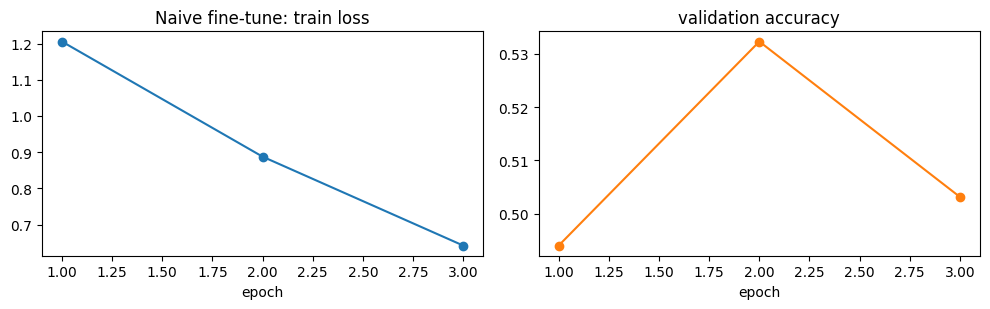

In [28]:
# (3) naive fine-tuning = our baseline
BASELINE_CFG = dict(name="A. Naive fine-tune", model=MODEL_NAME, lr=5e-5, epochs=3, bs=32,
                    schedule="constant", warmup=0.0, wd=0.0, clip=None, llrd=None,
                    label_smoothing=0.0, select_best=False)
RESULTS = train_and_eval(BASELINE_CFG)
plot_history(RESULTS["history"], "Naive fine-tune")

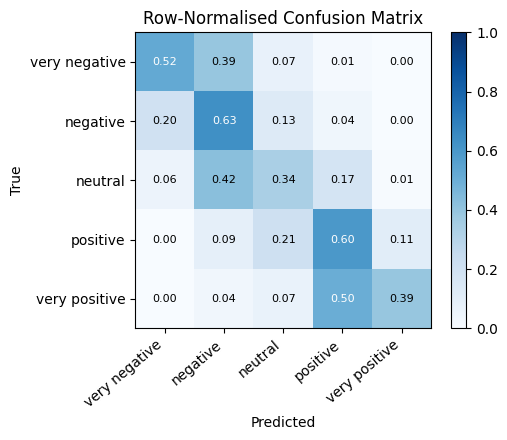

               precision    recall  f1-score   support

very negative      0.498     0.523     0.510       279
     negative      0.546     0.632     0.586       633
      neutral      0.356     0.337     0.346       389
     positive      0.506     0.596     0.547       510
very positive      0.726     0.391     0.508       399

     accuracy                          0.514      2210
    macro avg      0.526     0.496     0.500      2210
 weighted avg      0.530     0.514     0.511      2210



In [29]:

plot_confusion(RESULTS["test_logits"], RESULTS["test_labels"], "Row-Normalised Confusion Matrix")
print(classification_report(RESULTS["test_labels"].numpy(), RESULTS["test_logits"].argmax(-1).numpy(),
                            target_names=LABELS, digits=3))

### Interpretation: Section 3

Typical results (approximate; compare against the 28% majority baseline):

| Method | Test accuracy |
|---|---|
| Untrained head | about 20% (chance) |
| Frozen BERT + logistic regression | about 40-45% |
| Naive fine-tuning | about 50-54% |

- **Untrained head ≈ chance.** Pretraining gave BERT a general understanding of language, but it was never taught what "very negative" means. A task head and task labels are required.
- **Frozen features** already beat the majority baseline, so BERT's vectors contain sentiment information. But features trained for *predicting masked words* are not tuned for fine-grained sentiment.
- **Fine-tuning** adds roughly 10 points, because every layer can now specialise. This is the main payoff of the encoder approach.
- **Read the confusion matrix.** Bright cells should sit on the diagonal and **next to** it: the model's errors are overwhelmingly to a *neighbouring* class (negative vs. very negative, neutral vs. its two neighbours). The "within-1" accuracy is far higher than exact accuracy (usually 90%+), which is the signature of an ordinal problem with fuzzy boundaries rather than a model that "doesn't understand".
- **Learning curve.** If validation accuracy peaks early and then drops while train loss keeps falling, that is overfitting on only 8.5k examples. That motivates the techniques below.

## 5. Try your own input and compare with your own rating

Ratings use a **1-5 scale** here (1 = very negative, 5 = very positive). The model's output is a probability for each of the five classes. We show:

- **Predicted rating** = most likely class.
- **Expected rating** = probability-weighted average (e.g. 3.4 means "between neutral and positive"), a smoother view than the arg-max.

The table below has 10 example sentences with *my* guesses for a human rating in the `my_rating` column. **Edit these ratings (and the sentences) to match your own judgement**, then run the cell.

In [30]:
def rate(res, texts):
    model, tokenizer = res["model"].to(device), res["tokenizer"]
    model.eval()
    enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(device)
    with torch.no_grad():
        return model(**enc).logits.float().softmax(-1).cpu().numpy()

stars = np.arange(1, 6)

my_examples = [   # (sentence, my rating 1-5)  <- edit me!
    ("This is the best movie I have seen in years.", 5),
    ("A dull, lifeless film that wastes a great cast.", 1),
    ("It's not bad, but I wouldn't watch it again.", 3),
    ("The plot is predictable, yet the performances make it worth seeing.", 4),
    ("Oh great, another sequel nobody asked for.", 2),
    ("The film runs for two hours and is set in Chicago.", 3),
    ("Not a single moment of this movie is boring.", 5),
    ("I laughed, I cried, and I would happily watch it again.", 5),
    ("Mildly entertaining but forgettable.", 3),
    ("A complete disaster from start to finish.", 1),
]
ex = pd.DataFrame(my_examples, columns=["sentence", "my_rating"])

pA = rate(RESULTS, ex.sentence)

ex["baseline_pred"] = pA.argmax(1) + 1

pd.set_option("display.max_colwidth", 70)
display(ex)

for name, pred in [("Baseline A", ex.baseline_pred)]:
    err = (pred - ex.my_rating).abs()
    print(f"{name:>12}: exact match {np.mean(err == 0):.0%} | within 1 star {np.mean(err <= 1):.0%} | MAE {err.mean():.2f} stars")



,sentence,my_rating,baseline_pred
0,This is the best movie I have seen in years.,5,5
1,"A dull, lifeless film that wastes a great cast.",1,1
2,"It's not bad, but I wouldn't watch it again.",3,3
3,"The plot is predictable, yet the performances make it worth seeing.",4,4
4,"Oh great, another sequel nobody asked for.",2,4
5,The film runs for two hours and is set in Chicago.,3,2
6,Not a single moment of this movie is boring.,5,2
7,"I laughed, I cried, and I would happily watch it again.",5,5
8,Mildly entertaining but forgettable.,3,3
9,A complete disaster from start to finish.,1,1


  Baseline A: exact match 70% | within 1 star 80% | MAE 0.60 stars


Type a movie-review sentence: Good! 
Your own rating 1-5 (press Enter to skip): 4
Sentence: Good! 
  Baseline predicts   : 4  (expected 4.13)
  Your rating         : 4  ->  difference to the model: 0 star(s)


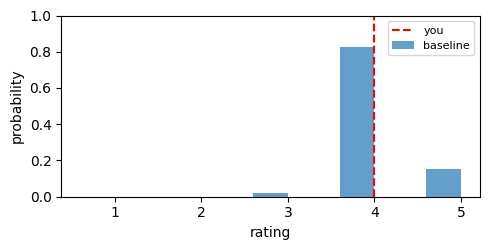

In [32]:
def try_it(text, my_rating=None):
    pa = rate(RESULTS, [text])[0]
    print(f"Sentence: {text}")
    print(f"  Baseline predicts   : {pa.argmax()+1}  (expected {np.dot(pa, stars):.2f})")
    if my_rating is not None:
        print(f"  Your rating         : {my_rating}  ->  difference to the model: {abs(pa.argmax()+1-my_rating)} star(s)")
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.bar(stars - 0.2, pa, width=0.4, label="baseline", alpha=0.7)

    if my_rating is not None: ax.axvline(my_rating, color="red", ls="--", label="you")
    ax.set_xticks(stars); ax.set_ylim(0, 1); ax.set_xlabel("rating"); ax.set_ylabel("probability"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

# Type your own sentence and rating below (works interactively in Colab):
user_text = input("Type a movie-review sentence: ")
user_rating = input("Your own rating 1-5 (press Enter to skip): ")
try_it(user_text, int(user_rating) if user_rating.strip() else None)

### Take-aways

1. **A pretrained encoder is not a classifier until you train it.** Untrained head ≈ chance; frozen features ≈ low 40s; fine-tuning ≈ low-to-mid 50s. The jump from frozen to fine-tuned is the central lesson of transfer learning with BERT.
2. **Training recipe matters more than tricks.** Lower learning rate, warm-up and decay were the reliable improvements. Smaller refinements (clipping, layer-wise decay, label smoothing) are cheap and sensible but their individual effect is often within seed noise. Verify with several seeds before believing a 1-point gain.
3. **SST-5 has a low ceiling (about 60%)** because the labels are bins cut from a continuous scale and annotators disagree. Most errors are to the *neighbouring* class, so judge models with **within-1 accuracy, MAE, macro-F1 and the confusion matrix**, not accuracy alone.
4. **Neutral and the mild classes are hardest; the extremes are easiest.** This matches the vocabulary analysis in Section 2.


### Things to try next

- **A stronger encoder:** Use roberta or DeBERTa-v3 and compare.
- **Phrase-level training data:** the original SST has about 215k labelled phrases; adding them is a classic way to boost SST-5 accuracy.
- **Ensembling** several seeds, or average the probabilities of the best few runs.
- **Compare with a decoder LLM** fine-tuned with LoRA/QLoRA on the same split to see whether the architecture matters here, or whether the label noise ceiling dominates.